In [ ]:
!pip install -q ultralytics kagglehub matplotlib seaborn pandas

import os
import shutil
import xml.etree.ElementTree as ET
import cv2
import yaml
import torch
import kagglehub
from ultralytics import YOLO

assert torch.cuda.is_available(), "Please switch Runtime -> Change runtime type -> T4 GPU!"
print(f"GPU Hardware : {torch.cuda.get_device_name(0)}")
print(f"Total VRAM   : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# 1. Pull Indian Vehicle Dataset from Kaggle cache
dataset_path = kagglehub.dataset_download("dataclusterlabs/indian-vehicle-dataset")

# 2. Organize 350 labeled images into train/val split for baseline evaluation
all_imgs, xmls = [], []
for root, _, fnames in os.walk(dataset_path):
  for f in fnames:
    fp = os.path.join(root, f)
    ext = os.path.splitext(f)[1].lower()
    if ext in {".jpg", ".jpeg", ".png"}:
      all_imgs.append(fp)
    elif ext == ".xml":
      xmls.append(fp)

yolo_ds = "/content/skill9_indian_vehicles"
if os.path.exists(yolo_ds):
  shutil.rmtree(yolo_ds)
for sub in ["images/train", "images/val", "labels/train", "labels/val"]:
  os.makedirs(os.path.join(yolo_ds, sub), exist_ok=True)

img_map = {os.path.splitext(os.path.basename(p))[0]: p for p in all_imgs}
class_list, valid_pairs = [], []

for xp in xmls:
  tree = ET.parse(xp)
  root = tree.getroot()
  stem = os.path.splitext(os.path.basename(xp))[0]
  if stem not in img_map:
    fn = root.find("filename")
    if fn is not None:
      stem = os.path.splitext(fn.text)[0]
  if stem not in img_map:
    continue
  img = cv2.imread(img_map[stem])
  if img is None:
    continue
  ih, iw, _ = img.shape
  lines = []
  for obj in root.findall("object"):
    cname = obj.find("name").text.strip()
    if cname not in class_list:
      class_list.append(cname)
    cid = class_list.index(cname)
    bnd = obj.find("bndbox")
    xmin, ymin = float(bnd.find("xmin").text), float(bnd.find("ymin").text)
    xmax, ymax = float(bnd.find("xmax").text), float(bnd.find("ymax").text)
    xc, yc = ((xmin + xmax) / 2.0) / iw, ((ymin + ymax) / 2.0) / ih
    bw, bh = (xmax - xmin) / iw, (ymax - ymin) / ih
    if 0 < bw <= 1 and 0 < bh <= 1:
      lines.append(f"{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
  if lines:
    valid_pairs.append((img_map[stem], stem, lines))

valid_pairs = valid_pairs[:350]
split_idx = max(1, int(0.8 * len(valid_pairs)))
for i, (ipath, stem, lines) in enumerate(valid_pairs):
  split = "train" if i < split_idx else "val"
  shutil.copy(ipath, f"{yolo_ds}/images/{split}/{stem}.jpg")
  with open(f"{yolo_ds}/labels/{split}/{stem}.txt", "w") as lf:
    lf.write("\n".join(lines))

data_yaml = f"{yolo_ds}/data.yaml"
with open(data_yaml, "w") as yf:
  yaml.dump({
      "path": yolo_ds,
      "train": "images/train",
      "val": "images/val",
      "nc": len(class_list),
      "names": class_list,
  }, yf)

# 3. Train Baseline YOLOv8n Model (10 epochs)
model = YOLO("yolov8n.pt")
model.train(
    data=data_yaml,
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs",
    name="skill9_baseline",
    exist_ok=True,
    verbose=False,
)

baseline_weights = "/content/runs/skill9_baseline/weights/best.pt"
print(f"\n[SUCCESS] Baseline model ready at: {baseline_weights}")
print(f"Classes ({len(class_list)}): {class_list}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU Hardware : Tesla T4
Total VRAM   : 14.56 GB
Using Colab cache for faster access to the 'indian-vehicle-dataset' dataset.
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/skill9_indian_vehicles/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, d

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6299.3±652.2 MB/s, size: 2896.1 KB)
val: Scanning /content/skill9_indian_vehicles/labels/val.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 6.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4s/it 2.8s
                   all         20         94      0.255      0.265      0.173       0.12
Speed: 9.6ms preprocess, 10.8ms inference, 0.0ms loss, 5.3ms postprocess per image
Results saved to /content/runs/detect/val
=== BASELINE ACCURACY & mAP REPORT ===
             Metric  Value
 Mean Precision (P) 0.2547
    Mean Recall (R) 0.2651
           F1-Score 0.2598
     mAP @ IoU=0.50 0.1730
mAP @ IoU=0.50:0.95 0.1199

=== PER-CLASS DETECTION ACCURACY ===
 Vehicle Class  Precision  Reca

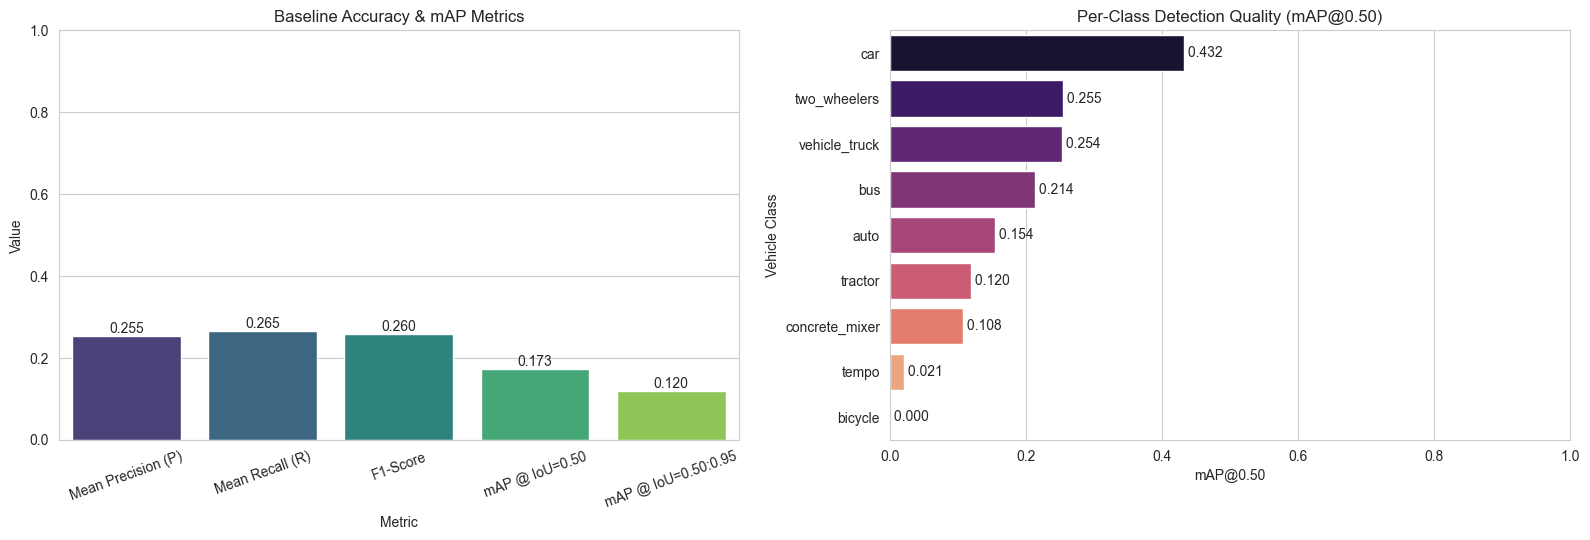

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

baseline_model = YOLO(baseline_weights)

# Run validation on held-out Indian vehicle images
val_metrics = baseline_model.val(
    data=data_yaml, imgsz=640, batch=16, device=0, verbose=False
)

precision = float(val_metrics.box.mp)
recall = float(val_metrics.box.mr)
f1_score = (
    (2 * precision * recall) / (precision + recall)
    if (precision + recall) > 0
    else 0.0
)
map50 = float(val_metrics.box.map50)
map50_95 = float(val_metrics.box.map)

df_accuracy = pd.DataFrame([
    {"Metric": "Mean Precision (P)", "Value": round(precision, 4)},
    {"Metric": "Mean Recall (R)", "Value": round(recall, 4)},
    {"Metric": "F1-Score", "Value": round(f1_score, 4)},
    {"Metric": "mAP @ IoU=0.50", "Value": round(map50, 4)},
    {"Metric": "mAP @ IoU=0.50:0.95", "Value": round(map50_95, 4)},
])

print("=== BASELINE ACCURACY & mAP REPORT ===")
print(df_accuracy.to_string(index=False))

# Per-class mAP@0.50 breakdown
per_class_rows = []
for idx, ap50 in enumerate(val_metrics.box.ap50):
  cname = val_metrics.names[idx]
  per_class_rows.append({
      "Vehicle Class": cname,
      "Precision": round(float(val_metrics.box.p[idx]), 4),
      "Recall": round(float(val_metrics.box.r[idx]), 4),
      "mAP@0.50": round(float(ap50), 4),
  })
df_per_class = pd.DataFrame(per_class_rows).sort_values(
    by="mAP@0.50", ascending=False
)

print("\n=== PER-CLASS DETECTION ACCURACY ===")
print(df_per_class.to_string(index=False))

# Plot Overall Accuracy/mAP & Per-Class mAP@0.50
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

b1 = sns.barplot(
    x="Metric",
    y="Value",
    data=df_accuracy,
    ax=axes[0],
    palette="viridis",
    hue="Metric",
    legend=False,
)
axes[0].set_title(
    "Baseline Accuracy & mAP Metrics", fontsize=12, fontweight="bold"
)
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis="x", rotation=20)
for bar in b1.patches:
  axes[0].annotate(
      f"{bar.get_height():.3f}",
      (bar.get_x() + bar.get_width() / 2, bar.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
  )

b2 = sns.barplot(
    x="mAP@0.50",
    y="Vehicle Class",
    data=df_per_class,
    ax=axes[1],
    palette="magma",
    hue="Vehicle Class",
    legend=False,
)
axes[1].set_title(
    "Per-Class Detection Quality (mAP@0.50)", fontsize=12, fontweight="bold"
)
axes[1].set_xlim(0, 1.0)
for bar in b2.patches:
  w = bar.get_width()
  axes[1].annotate(
      f" {w:.3f}",
      (w, bar.get_y() + bar.get_height() / 2),
      va="center",
      fontweight="bold",
  )

plt.tight_layout()
plt.savefig("/content/skill9_accuracy_map.png", dpi=150)
plt.show()

Select your test traffic image to benchmark Latency, FPS & VRAM:


Saving images (1).jpeg to images (1).jpeg

=== BASELINE LATENCY, THROUGHPUT & GPU MEMORY REPORT ===
 Baseline System Metric             Measured Value
      Mean Latency (ms)                   10.72 ms
Median Latency P50 (ms)                   10.34 ms
  Tail Latency P95 (ms)                   13.84 ms
  Tail Latency P99 (ms)                   16.02 ms
       Throughput (FPS)                   93.3 FPS
Peak GPU Allocated VRAM                  131.74 MB
 Peak GPU Reserved VRAM                  162.00 MB
  Model Checkpoint Size 6.20 MB (3,140,190 params)


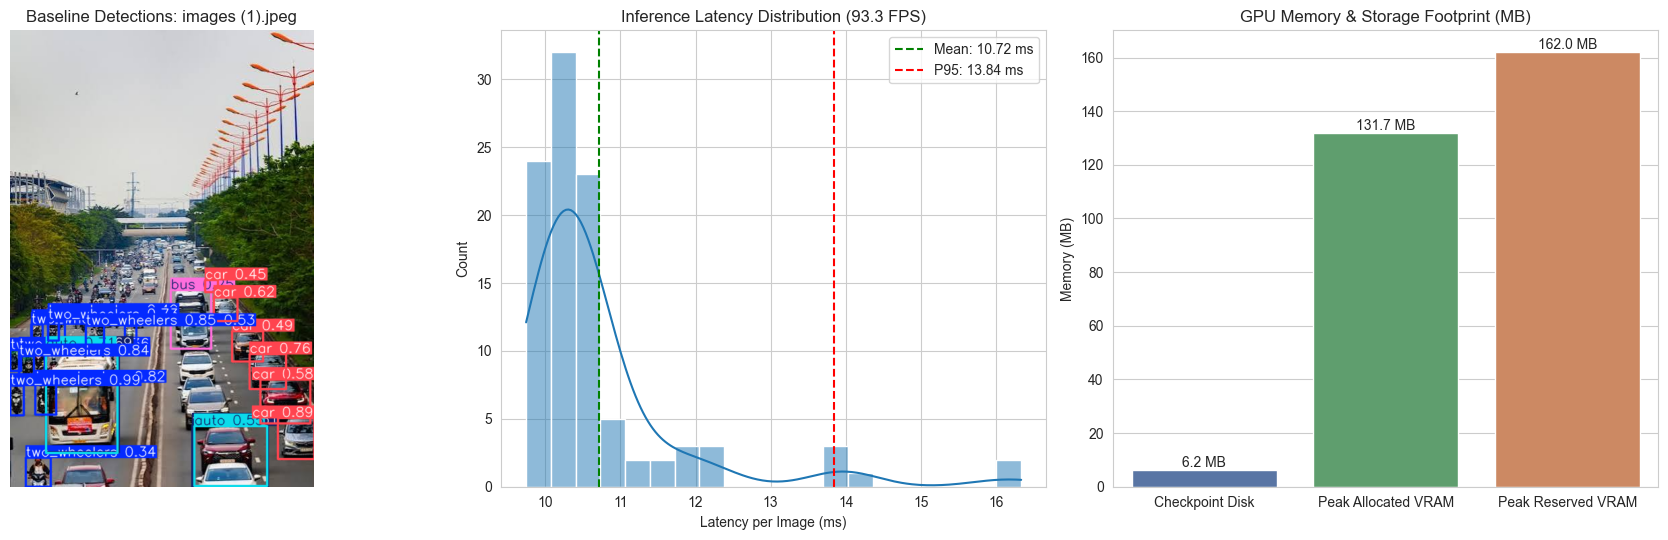

In [ ]:
import time
from google.colab import files

# 1. Upload your test traffic image from Mac Downloads
print("Select your test traffic image to benchmark Latency, FPS & VRAM:")
uploaded = files.upload()
test_img_path = list(uploaded.keys())[0]

# 2. Reset GPU memory counters & measure baseline model footprint
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

detector = YOLO(baseline_weights)
param_count = sum(p.numel() for p in detector.model.parameters())
disk_size_mb = os.path.getsize(baseline_weights) / (1024**2)

# Warmup GPU (10 runs)
for _ in range(10):
  _ = detector.predict(
      source=test_img_path, imgsz=640, device=0, conf=0.25, verbose=False
  )
torch.cuda.synchronize()

# 3. Timed Latency & Throughput Benchmark (100 runs)
latencies_ms = []
for _ in range(100):
  start_ev = torch.cuda.Event(enable_timing=True)
  end_ev = torch.cuda.Event(enable_timing=True)
  start_ev.record()
  preds = detector.predict(
      source=test_img_path, imgsz=640, device=0, conf=0.25, verbose=False
  )
  end_ev.record()
  torch.cuda.synchronize()
  latencies_ms.append(start_ev.elapsed_time(end_ev))

mean_lat = float(np.mean(latencies_ms))
p50_lat = float(np.percentile(latencies_ms, 50))
p95_lat = float(np.percentile(latencies_ms, 95))
p99_lat = float(np.percentile(latencies_ms, 99))
throughput_fps = 1000.0 / mean_lat

peak_allocated_mb = torch.cuda.max_memory_allocated() / (1024**2)
peak_reserved_mb = torch.cuda.max_memory_reserved() / (1024**2)

df_perf = pd.DataFrame([
    {"Baseline System Metric": "Mean Latency (ms)", "Measured Value": f"{mean_lat:.2f} ms"},
    {"Baseline System Metric": "Median Latency P50 (ms)", "Measured Value": f"{p50_lat:.2f} ms"},
    {"Baseline System Metric": "Tail Latency P95 (ms)", "Measured Value": f"{p95_lat:.2f} ms"},
    {"Baseline System Metric": "Tail Latency P99 (ms)", "Measured Value": f"{p99_lat:.2f} ms"},
    {"Baseline System Metric": "Throughput (FPS)", "Measured Value": f"{throughput_fps:.1f} FPS"},
    {"Baseline System Metric": "Peak GPU Allocated VRAM", "Measured Value": f"{peak_allocated_mb:.2f} MB"},
    {"Baseline System Metric": "Peak GPU Reserved VRAM", "Measured Value": f"{peak_reserved_mb:.2f} MB"},
    {"Baseline System Metric": "Model Checkpoint Size", "Measured Value": f"{disk_size_mb:.2f} MB ({param_count:,} params)"},
])

print("\n=== BASELINE LATENCY, THROUGHPUT & GPU MEMORY REPORT ===")
print(df_perf.to_string(index=False))

# 4. Plot Test Image Detections + Latency Histogram + GPU Memory Breakdown
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: Annotated Test Image
annotated_rgb = cv2.cvtColor(preds[0].plot(), cv2.COLOR_BGR2RGB)
axes[0].imshow(annotated_rgb)
axes[0].set_title(
    f"Baseline Detections: {test_img_path}", fontsize=12, fontweight="bold"
)
axes[0].axis("off")

# Panel 2: Latency Distribution Across 100 Runs
sns.histplot(
    latencies_ms, bins=20, kde=True, color="#1f77b4", ax=axes[1]
)
axes[1].axvline(mean_lat, color="green", linestyle="--", label=f"Mean: {mean_lat:.2f} ms")
axes[1].axvline(p95_lat, color="red", linestyle="--", label=f"P95: {p95_lat:.2f} ms")
axes[1].set_title(
    f"Inference Latency Distribution ({throughput_fps:.1f} FPS)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Latency per Image (ms)")
axes[1].legend()

# Panel 3: GPU Memory Footprint Breakdown
mem_labels = ["Checkpoint Disk", "Peak Allocated VRAM", "Peak Reserved VRAM"]
mem_values = [disk_size_mb, peak_allocated_mb, peak_reserved_mb]
b3 = sns.barplot(
    x=mem_labels,
    y=mem_values,
    ax=axes[2],
    palette=["#4c72b0", "#55a868", "#dd8452"],
    hue=mem_labels,
    legend=False,
)
axes[2].set_title(
    "GPU Memory & Storage Footprint (MB)", fontsize=12, fontweight="bold"
)
axes[2].set_ylabel("Memory (MB)")
for bar in b3.patches:
  axes[2].annotate(
      f"{bar.get_height():.1f} MB",
      (bar.get_x() + bar.get_width() / 2, bar.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt.tight_layout()
plt.savefig("/content/skill9_latency_memory_baseline.png", dpi=150)
plt.show()